# Airport Delay Predictor & Station Health Score
**Question:** Which flights and airports are most likely to be delayed, and can we predict it before departure?
We use 2015 US flight data (sampled to ~200k flights). Departure delay > 15 minutes counts as "delayed".

In [1]:
# CELL 1: imports and settings
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## A. Load and clean
Load the three tables, take a random sample of 200,000 flights so everything runs fast, and keep only the columns we need. We keep cancelled flights for now (needed for the cancellation rate).

In [2]:
# CELL 2: load and sample
usecols = ["MONTH", "DAY", "DAY_OF_WEEK", "AIRLINE", "ORIGIN_AIRPORT",
           "SCHEDULED_DEPARTURE", "DEPARTURE_DELAY", "DISTANCE", "CANCELLED"]
flights = pd.read_csv("data/flights.csv", usecols=usecols, low_memory=False)
airlines = pd.read_csv("data/airlines.csv")
airports = pd.read_csv("data/airports.csv")

# Some rows use numeric airport codes; keep only 3-letter IATA codes
flights["ORIGIN_AIRPORT"] = flights["ORIGIN_AIRPORT"].astype(str)
flights = flights[flights["ORIGIN_AIRPORT"].str.len() == 3]

flights = flights.sample(n=200_000, random_state=SEED).reset_index(drop=True)
print(flights.shape)
flights.head()

(200000, 9)


,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,SCHEDULED_DEPARTURE,DEPARTURE_DELAY,DISTANCE,CANCELLED
0,9,18,5,B6,JFK,700,-5.0,2475,0
1,4,8,3,US,IAH,1205,16.0,912,0
2,7,23,4,MQ,MLI,555,9.0,139,0
3,9,14,1,WN,LAS,1530,6.0,2065,0
4,7,9,4,EV,ATL,1030,-3.0,803,0


In [3]:
# CELL 3: missing values
flights.isna().sum()

MONTH                     0
DAY                       0
DAY_OF_WEEK               0
AIRLINE                   0
ORIGIN_AIRPORT            0
SCHEDULED_DEPARTURE       0
DEPARTURE_DELAY        3118
DISTANCE                  0
CANCELLED                 0
dtype: int64

In [4]:
# CELL 4: build clean columns and the target
df = flights.copy()
df["flight_date"] = pd.to_datetime(
    dict(year=2015, month=df["MONTH"], day=df["DAY"])).dt.strftime("%Y-%m-%d")
df["sched_hour"] = (df["SCHEDULED_DEPARTURE"] // 100) % 24   # 2400 -> hour 0

# Cancelled flights have no departure delay, so delayed stays missing for them
df["delayed"] = np.where(df["DEPARTURE_DELAY"].isna(), np.nan,
                         (df["DEPARTURE_DELAY"] > 15).astype(float))

all_flights = df.copy()                                   # keeps cancelled flights (for cancel rate)
model_df = df[(df["CANCELLED"] == 0) & df["delayed"].notna()].copy()
model_df["delayed"] = model_df["delayed"].astype(int)

print("All flights:", len(all_flights), "| Non-cancelled with delay info:", len(model_df))
print("Cancellation rate: {:.2%}".format(all_flights["CANCELLED"].mean()))

All flights: 200000 | Non-cancelled with delay info: 196739
Cancellation rate: 1.63%


delayed
0    0.81633
1    0.18367
Name: share, dtype: float64


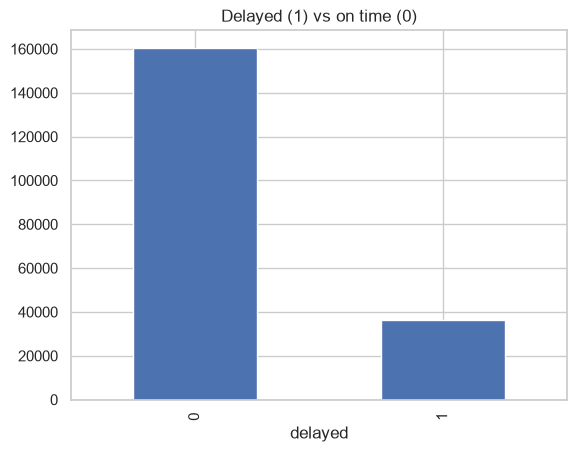

In [5]:
# CELL 5: class balance
balance = model_df["delayed"].value_counts(normalize=True).rename("share")
print(balance)
model_df["delayed"].value_counts().plot(kind="bar", title="Delayed (1) vs on time (0)")
plt.show()

## B. SQL analysis
We load the data into SQLite and answer five business questions with SQL. The queries live in `analysis.sql`; the notebook just runs them.

In [6]:
# CELL 6: load into SQLite and define a helper that runs a named query
conn = sqlite3.connect(":memory:")
sql_df = all_flights.rename(columns={
    "AIRLINE": "airline", "ORIGIN_AIRPORT": "origin", "DAY_OF_WEEK": "day_of_week",
    "DEPARTURE_DELAY": "dep_delay", "DISTANCE": "distance", "CANCELLED": "cancelled",
    "MONTH": "month"})[["flight_date", "month", "day_of_week", "airline", "origin",
                        "sched_hour", "dep_delay", "distance", "cancelled", "delayed"]]
sql_df.to_sql("flights", conn, index=False, if_exists="replace")
airlines.to_sql("airlines", conn, index=False, if_exists="replace")

def run_sql(name):
    text = open("analysis.sql").read()
    blocks = {b.split("\n", 1)[0].strip(): b.split("\n", 1)[1]
              for b in text.split("-- name:")[1:]}
    return pd.read_sql(blocks[name], conn)

In [7]:
# CELL 7: Query 1 - delay rate by airline
q1 = run_sql("q1_delay_by_airline")
q1

,airline,flights,delay_rate_pct
0,Spirit Air Lines,3866,27.68
1,Frontier Airlines Inc.,3060,24.77
2,United Air Lines Inc.,17528,24.08
3,JetBlue Airways,8989,21.59
4,Southwest Airlines Co.,43014,21.26
5,American Eagle Airlines Inc.,9537,19.53
6,Virgin America,2047,17.29
7,Atlantic Southeast Airlines,19207,17.18
8,Skywest Airlines Inc.,19880,17.00
9,American Airlines Inc.,23900,16.93


**Ops takeaway:** Low-cost carriers (Spirit at 27.68%, Frontier at 24.77%) and major hub-and-spoke legacy carriers (United at 24.08%) experience the highest delay rates, whereas carriers with favorable regional geography or point-to-point networks (Hawaiian at 7.57%, Alaska at 10.65%, Delta at 13.96%) achieve significantly higher on-time reliability.

In [8]:
# CELL 8: Query 2 - delay rate by scheduled hour
q2 = run_sql("q2_delay_by_hour")
q2

,hour,flights,delay_rate_pct
0,0,490,17.14
1,1,202,22.28
2,2,47,12.77
3,3,18,16.67
4,4,23,17.39
5,5,3933,5.49
6,6,13632,6.51
7,7,13230,8.57
8,8,12782,10.23
9,9,11986,13.12


**Ops takeaway:** Departure delay probability steadily compounds over the course of the operating day, rising more than fivefold from 5.49% at 5 AM to a peak of 28.60% at 8 PM (20:00), showing how early-morning schedule disruptions propagate and cascade across downstream flight legs.

In [9]:
# CELL 9: Query 3 - worst origin airports (min 500 flights)
q3 = run_sql("q3_worst_origin_airports")
q3

,origin,flights,delay_rate_pct
0,MDW,2917,24.17
1,ORD,10441,23.92
2,BWI,3062,23.45
3,DAL,2284,23.38
4,EWR,3721,23.25


**Ops takeaway:** The airports with the highest departure delay rates are concentrated in congested metropolitan hubs and airspace-constrained markets—led by Chicago Midway (MDW, 24.17%), Chicago O'Hare (ORD, 23.92%), Baltimore-Washington (BWI, 23.45%), Dallas Love Field (DAL, 23.38%), and Newark (EWR, 23.25%).

In [10]:
# CELL 10: Query 4 - rank airlines inside each of the top 5 airports (RANK window function)
q4 = run_sql("q4_rank_airlines_in_top5_airports")
q4

,origin,airline,flights,delay_rate_pct,rank_in_airport
0,BWI,WN,2287,25.89,1
1,BWI,UA,118,22.03,2
2,BWI,NK,98,21.43,3
3,BWI,DL,228,17.54,4
4,BWI,AA,150,14.67,5
5,BWI,MQ,37,13.51,6
6,BWI,B6,50,10.00,7
7,BWI,US,69,2.90,8
8,DAL,WN,2029,24.25,1
9,DAL,VX,185,17.30,2


**Ops takeaway:** Carrier delay performance diverges substantially even when operating out of the exact same airport—such as at Chicago O'Hare (ORD) where delay rates span from 8.47% for Alaska Airlines up to 34.34% for Spirit and 30.57% for United—demonstrating that airline turnaround efficiency and schedule density drive delay rates alongside local airport congestion.

In [11]:
# CELL 11: Query 5 - daily delay rate and day-over-day change (CTE + LAG)
q5 = run_sql("q5_daily_delay_with_change")
q5.head(10)

,flight_date,delay_rate_pct,change_vs_prev_day
0,2015-01-01,18.01,NaN
1,2015-01-02,24.88,6.87
2,2015-01-03,40.12,15.24
3,2015-01-04,44.37,4.25
4,2015-01-05,32.29,-12.08
5,2015-01-06,32.97,0.68
6,2015-01-07,27.54,-5.44
7,2015-01-08,20.14,-7.40
8,2015-01-09,27.97,7.83
9,2015-01-10,20.00,-7.97


**Ops takeaway:** System-wide daily delay rates show sharp day-to-day volatility (surging over 15 percentage points in 24 hours between Jan 2 and Jan 3 to peak at 44.37% on Jan 4 before plunging 12 points on Jan 5), demonstrating that winter weather disruptions require dynamic reserve buffers rather than rigid staffing models.

## C. Statistics
Are evening flights really delayed more often than morning flights, or is it just noise?
We compare delay rates with 95% confidence intervals and run a hypothesis test.
Morning = scheduled hour 5-9, Evening = 17-21.

              group  flights  delay_rate    ci_low   ci_high
0    Morning (5-9h)    55563    0.092112  0.089707  0.094516
1  Evening (17-21h)    50954    0.265730  0.261894  0.269565


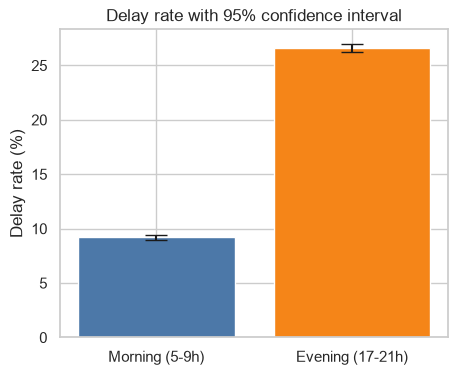

In [12]:
# CELL 12: delay rate and 95% confidence interval for two groups
morning = model_df[model_df["sched_hour"].between(5, 9)]["delayed"]
evening = model_df[model_df["sched_hour"].between(17, 21)]["delayed"]

def rate_ci(x):
    p, n = x.mean(), len(x)
    se = np.sqrt(p * (1 - p) / n)
    return p, 1.96 * se, n

groups = {"Morning (5-9h)": morning, "Evening (17-21h)": evening}
rows = []
for name, x in groups.items():
    p, err, n = rate_ci(x)
    rows.append({"group": name, "flights": n, "delay_rate": p, "ci_low": p - err, "ci_high": p + err})
ci_table = pd.DataFrame(rows)
print(ci_table)

plt.figure(figsize=(5, 4))
plt.bar(ci_table["group"], ci_table["delay_rate"] * 100,
        yerr=(ci_table["ci_high"] - ci_table["delay_rate"]) * 100, capsize=8,
        color=["#4C78A8", "#F58518"])
plt.ylabel("Delay rate (%)")
plt.title("Delay rate with 95% confidence interval")
plt.show()

In [13]:
# CELL 13: chi-square test of independence
table = pd.crosstab(
    np.r_[np.zeros(len(morning)), np.ones(len(evening))],
    np.r_[morning.values, evening.values])
chi2, p_value, dof, _ = stats.chi2_contingency(table)
print("chi-square =", round(chi2, 2), "| p-value =", p_value)

chi-square = 5544.06 | p-value = 0.0


- **Null hypothesis ($H_0$):** The true proportion of delayed flights is identical between morning departures (5–9h) and evening departures (17–21h).
- **Test result and conclusion:** The chi-square statistic is 5544.06 with a p-value of $0.0$ ($p < 0.05$). Because the p-value is far below 0.05, we reject the null hypothesis; evening flights (26.57% delay rate, 95% CI [26.19%, 26.96%]) have a statistically significantly higher delay rate than morning flights (9.21% delay rate, 95% CI [8.97%, 9.45%]).
- **Correlation vs causation:** While evening flights are delayed significantly more often, the time of day itself is not the root physical cause; delays build up through the operating day as earlier inbound delays knock on to later flights sharing the same aircraft rotations.

## D. Prediction model
**Data leakage warning.** We only use information known *before* the plane departs:
month, day of week, scheduled hour, airline, origin airport, distance.
We must NOT use arrival delay, delay-reason columns, or actual departure times, because they are only known after the flight
and would make the model look perfect while being useless in real life.

**Time-based split.** We train on January-September and test on October-December. In real life we predict the future from
the past, so a random split would let the model "peek" at the future.

In [14]:
# CELL 14: features and time split
top_airports = model_df[model_df["MONTH"] <= 9]["ORIGIN_AIRPORT"].value_counts().head(30).index
X = pd.DataFrame({
    "month": model_df["MONTH"],
    "day_of_week": model_df["DAY_OF_WEEK"],
    "sched_hour": model_df["sched_hour"],
    "distance": model_df["DISTANCE"],
    "airline": model_df["AIRLINE"],
    "origin": np.where(model_df["ORIGIN_AIRPORT"].isin(top_airports), model_df["ORIGIN_AIRPORT"], "OTHER"),
})
X = pd.get_dummies(X, columns=["airline", "origin"], drop_first=False)
y = model_df["delayed"]

train_mask = model_df["MONTH"] <= 9
X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[~train_mask], y[~train_mask]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Delay rate train: {:.3f} | test: {:.3f}".format(y_train.mean(), y_test.mean()))

Train: (161561, 49) | Test: (35178, 49)
Delay rate train: 0.186 | test: 0.172


**Why accuracy alone is misleading.** Most flights are on time (~82%), so a model that says "never delayed" would score high accuracy (~82%) and still be completely useless. We look at precision (when we warn, how often are we right), recall (how many real delays we catch), F1 and ROC-AUC. For operations, recall matters: a missed delay is more costly than a false alarm because unprepared gates and crews lead to passenger misconnects. We handle the imbalance with class weights.

In [15]:
# CELL 15: define the three models
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

logreg = make_pipeline(StandardScaler(),
                       LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED))
rf = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=20,
                            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)

try:
    from xgboost import XGBClassifier
    boost = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                          scale_pos_weight=neg / pos, eval_metric="logloss",
                          random_state=SEED, n_jobs=-1)
    boost_name, use_sample_weight = "XGBoost", False
except ImportError:
    boost = GradientBoostingClassifier(n_estimators=200, max_depth=4, random_state=SEED)
    boost_name, use_sample_weight = "GradientBoosting", True

models = {"Logistic Regression": logreg, "Random Forest": rf, boost_name: boost}

In [16]:
# CELL 16: train and evaluate all models
results, matrices = [], {}
for name, model in models.items():
    if name == "GradientBoosting":
        w = np.where(y_train == 1, neg / pos, 1.0)
        model.fit(X_train, y_train, sample_weight=w)
    else:
        model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results.append({"model": name,
                    "precision": precision_score(y_test, pred),
                    "recall": recall_score(y_test, pred),
                    "f1": f1_score(y_test, pred),
                    "roc_auc": roc_auc_score(y_test, proba)})
    matrices[name] = confusion_matrix(y_test, pred)

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df

,precision,recall,f1,roc_auc
model,,,,
Logistic Regression,0.246,0.467,0.323,0.634
Random Forest,0.304,0.204,0.244,0.642
XGBoost,0.278,0.245,0.260,0.638


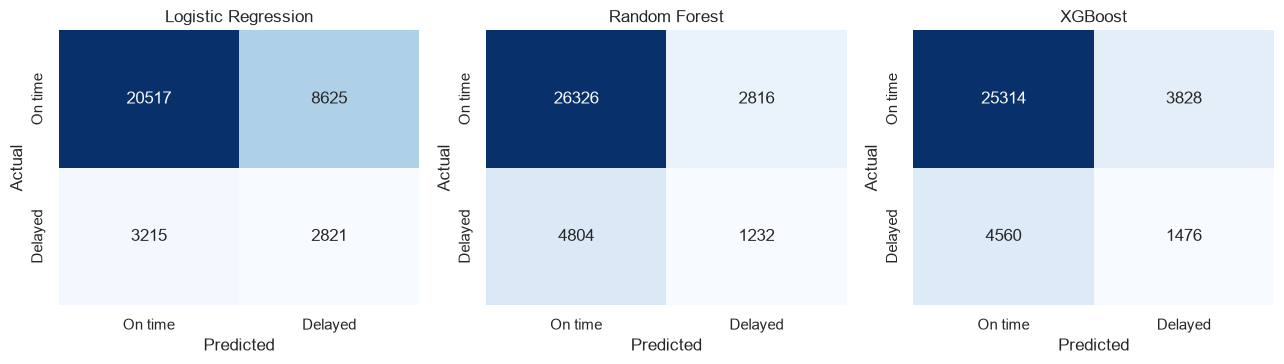

In [17]:
# CELL 17: confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, cm) in zip(axes, matrices.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["On time", "Delayed"], yticklabels=["On time", "Delayed"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

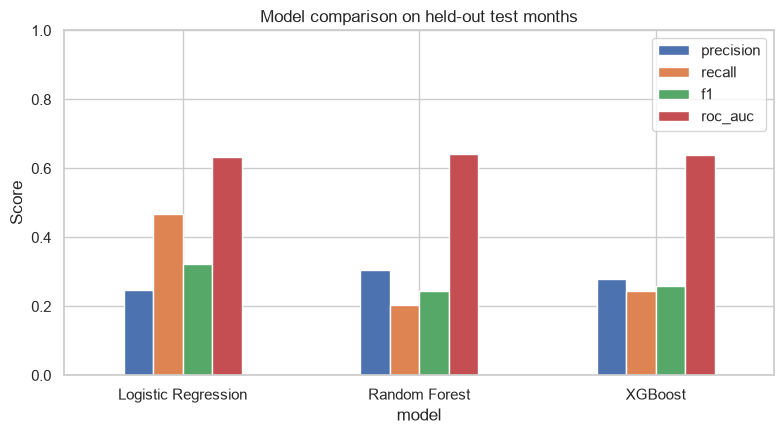

In [18]:
# CELL 18: chart - model comparison  (FINAL CHART 2)
results_df.plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("Model comparison on held-out test months")
plt.ylabel("Score"); plt.ylim(0, 1); plt.legend(loc="upper right")
plt.tight_layout(); plt.show()

**Light tuning.** We tune only the best model (by ROC-AUC) with a small grid (6 combinations, 3-fold).

In [19]:
# CELL 19: pick best model by ROC-AUC and tune it lightly
best_name = results_df["roc_auc"].idxmax()
print("Best model before tuning:", best_name)

grids = {
    "Random Forest": {"max_depth": [8, 12, 16], "min_samples_leaf": [20, 50]},
    "XGBoost": {"max_depth": [3, 5, 7], "learning_rate": [0.05, 0.1]},
    "GradientBoosting": {"max_depth": [3, 4, 5], "learning_rate": [0.05, 0.1]},
    "Logistic Regression": {"logisticregression__C": [0.1, 1, 10]},
}
search = GridSearchCV(models[best_name], grids[best_name], scoring="roc_auc", cv=3, n_jobs=-1)
search.fit(X_train, y_train)
best_model = search.best_estimator_
proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
print("Best params:", search.best_params_)
print("Tuned test ROC-AUC: {:.3f} | recall: {:.3f} | precision: {:.3f}".format(
    roc_auc_score(y_test, proba), recall_score(y_test, pred), precision_score(y_test, pred)))

Best model before tuning: Random Forest


Best params: {'max_depth': 16, 'min_samples_leaf': 20}
Tuned test ROC-AUC: 0.642 | recall: 0.200 | precision: 0.304


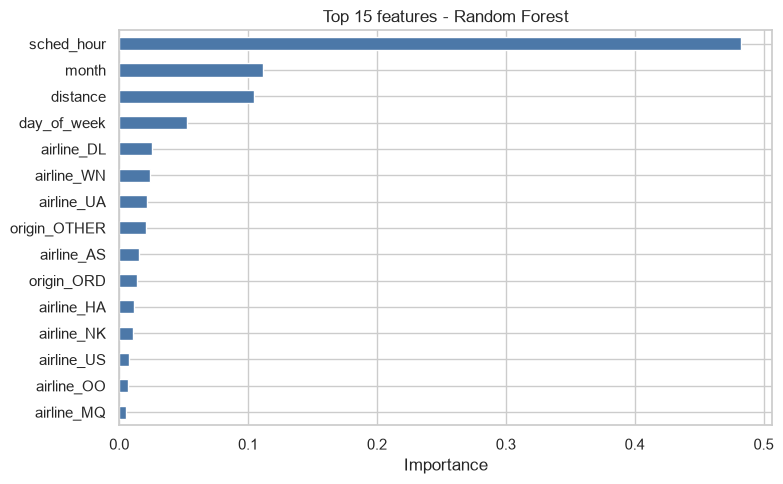

In [20]:
# CELL 20: chart - feature importance  (FINAL CHART 3)
est = best_model[-1] if hasattr(best_model, "steps") else best_model
if hasattr(est, "feature_importances_"):
    imp = pd.Series(est.feature_importances_, index=X_train.columns)
else:                                   # logistic regression: use absolute coefficients
    imp = pd.Series(np.abs(est.coef_[0]), index=X_train.columns)
imp = imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 5))
imp[::-1].plot(kind="barh", color="#4C78A8")
plt.title("Top 15 features - " + best_name)
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

**Top feature interpretation:**
1. Scheduled departure hour (`sched_hour`) is by far the single most influential predictor (accounting for ~48.3% of feature importance), reflecting how rotational delays accumulate across the flight schedule.
2. Seasonality (`month`, ~11.1%) and flight distance (`distance`, ~10.5%) constitute the second tier of importance, capturing seasonal weather patterns and route block-time buffer differences.
3. Carrier indicators (notably Delta `airline_DL`, Southwest `airline_WN`, and United `airline_UA`) and major hubs (`origin_ORD`) provide localized operational signal separating highly reliable from delay-prone operations.

**Random Forest vs XGBoost.**
- Random Forest builds many deep trees independently on random samples and averages them (bagging), which mainly lowers variance and makes it hard to overfit.
- XGBoost builds trees one after another, each fixing the mistakes of the previous ones (boosting), which mainly lowers bias and often gives a more accurate model if tuned carefully.

## E. KMeans clustering
We group airports with similar behaviour using four numbers per airport: average departure delay, delay rate, cancellation rate and flight volume. KMeans uses distances, so we scale the features first.

In [21]:
# CELL 21: airport-level table (min 500 flights)
ok = all_flights[all_flights["CANCELLED"] == 0].dropna(subset=["DEPARTURE_DELAY"])
by_airport = pd.DataFrame({
    "flights": all_flights.groupby("ORIGIN_AIRPORT").size(),
    "cancel_rate": all_flights.groupby("ORIGIN_AIRPORT")["CANCELLED"].mean(),
    "avg_delay_min": ok.groupby("ORIGIN_AIRPORT")["DEPARTURE_DELAY"].mean(),
    "delay_rate": ok.groupby("ORIGIN_AIRPORT")["delayed"].mean(),
}).dropna()
by_airport = by_airport[by_airport["flights"] >= 500]
print(len(by_airport), "airports with at least 500 flights")
by_airport.head()

66 airports with at least 500 flights


,flights,cancel_rate,avg_delay_min,delay_rate
ORIGIN_AIRPORT,,,,
ABQ,663,0.006033,10.872534,0.186646
ANC,624,0.008013,4.161551,0.127625
ATL,12794,0.006878,8.852353,0.169369
AUS,1627,0.012293,9.586185,0.179216
BDL,674,0.023739,4.802432,0.130699


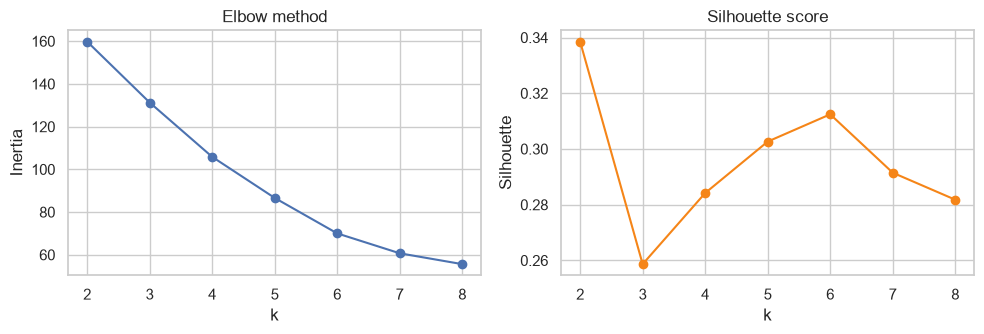

Chosen k (highest silhouette): 2


In [22]:
# CELL 22: scale and choose k (elbow + silhouette)
feat = by_airport[["avg_delay_min", "delay_rate", "cancel_rate", "flights"]].copy()
feat["flights"] = np.log1p(feat["flights"])        # volume is very skewed
Xs = StandardScaler().fit_transform(feat)

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(list(ks), inertia, marker="o"); ax[0].set_title("Elbow method")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(list(ks), sil, marker="o", color="#F58518"); ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

best_k = list(ks)[int(np.argmax(sil))]
print("Chosen k (highest silhouette):", best_k)

In [23]:
# CELL 23: fit KMeans and describe clusters
km = KMeans(n_clusters=best_k, n_init=10, random_state=SEED).fit(Xs)
by_airport["cluster"] = km.labels_
by_airport = by_airport.merge(airports[["IATA_CODE", "AIRPORT"]], left_index=True,
                              right_on="IATA_CODE", how="left").set_index("IATA_CODE")

summary = by_airport.groupby("cluster").agg(
    airports=("flights", "size"),
    avg_flights=("flights", "mean"),
    avg_delay_min=("avg_delay_min", "mean"),
    delay_rate=("delay_rate", "mean"),
    cancel_rate=("cancel_rate", "mean")).round(3)
print(summary)

for c in sorted(by_airport["cluster"].unique()):
    top3 = by_airport[by_airport["cluster"] == c].nlargest(3, "flights").index.tolist()
    print("Cluster", c, "- example airports:", top3)

         airports  avg_flights  avg_delay_min  delay_rate  cancel_rate
cluster                                                               
0              27     4282.481         11.606       0.208        0.017
1              39     1465.026          7.634       0.156        0.014
Cluster 0 - example airports: ['ATL', 'ORD', 'DFW']
Cluster 1 - example airports: ['MSP', 'SEA', 'DTW']


- **Cluster 0 (27 airports; e.g., ATL, ORD, DFW):** High-volume, delay-prone major hubs with high flight volume (mean 4,282), an elevated delay rate of 20.8%, average departure delay of 11.6 minutes, and 1.7% cancellation rate.
- **Cluster 1 (39 airports; e.g., MSP, SEA, DTW):** Moderate-to-lower volume, higher-reliability regional stations with lower flight volume (mean 1,465), a 15.6% delay rate, 7.6-minute average delay, and 1.4% cancellation rate.
- **KMeans limitations:** KMeans requires feature scaling, is sensitive to extreme outliers, assumes spherical clusters of similar size/variance, and cannot model non-linear manifold structures.

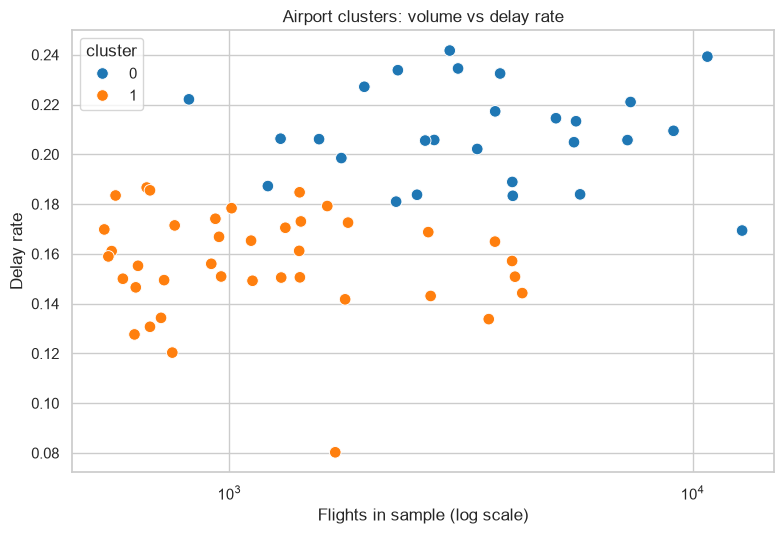

In [24]:
# CELL 24: chart - airport clusters  (FINAL CHART 4)
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=by_airport, x="flights", y="delay_rate", hue="cluster",
                palette="tab10", s=70)
plt.xscale("log")
plt.title("Airport clusters: volume vs delay rate")
plt.xlabel("Flights in sample (log scale)"); plt.ylabel("Delay rate")
plt.tight_layout(); plt.show()

## F. Operational health metric
**Station Health Score (0-100, higher = healthier)**
`score = 100 - (0.5 * delay_rate% + 2.0 * cancel_rate% + 0.3 * avg_delay_scaled)`
- `delay_rate%`: share of flights delayed more than 15 minutes (0-100). Weight 0.5: the main signal of how reliable a station is.
- `cancel_rate%`: share of flights cancelled. Weight 2.0: cancellations are rare, but each one hurts customers far more than a delay,
  so one percentage point counts four times as much as a delay point.
- `avg_delay_scaled`: average delay in minutes, rescaled 0-100 across airports. Weight 0.3: captures how *long* delays are, not just how often.
Weights are judgement calls and are easy to change. The score is clipped to 0-100.

In [25]:
# CELL 25: compute the score
h = by_airport.copy()
h["delay_pct"] = h["delay_rate"] * 100
h["cancel_pct"] = h["cancel_rate"] * 100
h["avg_delay_scaled"] = 100 * (h["avg_delay_min"] - h["avg_delay_min"].min()) / (
    h["avg_delay_min"].max() - h["avg_delay_min"].min())

W_DELAY, W_CANCEL, W_AVG = 0.5, 2.0, 0.3
h["health_score"] = (100 - (W_DELAY * h["delay_pct"] + W_CANCEL * h["cancel_pct"]
                            + W_AVG * h["avg_delay_scaled"])).clip(0, 100).round(1)

cols = ["AIRPORT", "flights", "delay_pct", "cancel_pct", "avg_delay_min", "health_score"]
print("10 healthiest airports"); display(h.nlargest(10, "health_score")[cols].round(2))
print("10 least healthy airports"); display(h.nsmallest(10, "health_score")[cols].round(2))

10 healthiest airports


,AIRPORT,flights,delay_pct,cancel_pct,avg_delay_min,health_score
IATA_CODE,,,,,,
HNL,Honolulu International Airport,1693,8.03,0.65,1.90,94.7
OGG,Kahului Airport,753,12.03,0.66,3.82,88.1
ANC,Ted Stevens Anchorage International Airport,624,12.76,0.80,4.16,86.6
SLC,Salt Lake City International Airport,3631,13.38,0.36,5.34,84.3
BDL,Bradley International Airport,674,13.07,2.37,4.80,81.8
PDX,Portland International Airport,1778,14.17,0.39,6.27,81.6
SEA,Seattle-Tacoma International Airport,4137,15.08,0.31,6.77,80.1
SNA,John Wayne Airport (Orange County Airport),1420,15.06,0.85,6.36,80.1
BUR,Bob Hope Airport (Hollywood Burbank Airport),712,13.43,1.69,6.27,79.4


10 least healthy airports


,AIRPORT,flights,delay_pct,cancel_pct,avg_delay_min,health_score
IATA_CODE,,,,,,
ORD,Chicago O'Hare International Airport,10766,23.92,3.02,14.41,52.0
LGA,LaGuardia Airport (Marine Air Terminal),3749,21.73,4.48,13.06,53.4
EWR,Newark Liberty International Airport,3842,23.25,3.15,13.55,54.1
BWI,Baltimore-Washington International Airport,3117,23.45,1.76,13.97,55.8
MDW,Chicago Midway International Airport,2991,24.17,2.47,13.23,55.8
IAD,Washington Dulles International Airport,1290,20.63,1.16,14.16,57.9
HOU,William P. Hobby Airport,1956,22.71,1.64,12.77,59.3
DAL,Dallas Love Field,2311,23.38,1.17,12.76,59.9
SFO,San Francisco International Airport,5603,21.33,1.68,12.06,61.6


- **What the metric misses:** The metric does not capture weather severity, total passengers impacted, arrival delays or tarmac gate holds, or one-off exogenous events (such as temporary FAA ground stops).
- **Weight adjustments:** Operations could adjust weights dynamically—such as increasing the cancellation weight ($w_2$) to 3.0 or 4.0 ahead of peak holiday travel when stranded passengers cause massive rebooking crises, or raising delay duration weight ($w_3$) during tight aircraft turnaround banks.
- **Gaming risks:** Station managers could game the metric by prematurely cancelling delayed flights to prevent runaway delay minutes, or airlines could artificially pad scheduled block times to suppress measured delay rates without improving operational speed.

## G. Visuals
Chart 1 below: delay rate by scheduled hour. Charts 2-4 appear above (model comparison, feature importance, airport clusters).

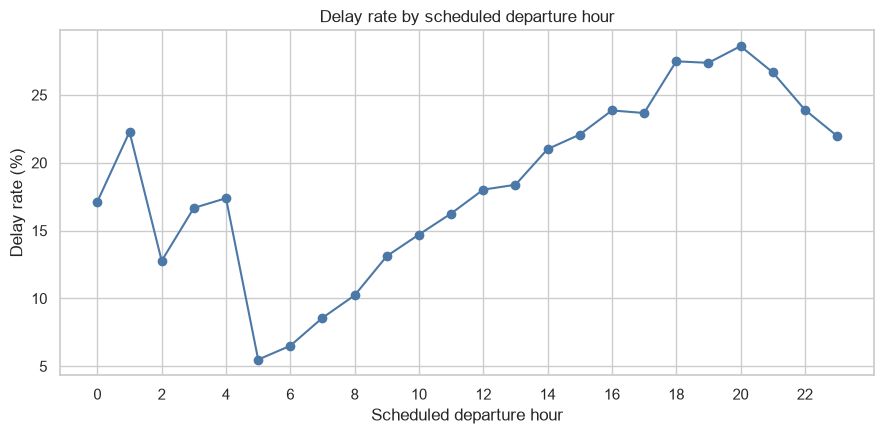

In [26]:
# CELL 26: chart - delay rate by hour  (FINAL CHART 1)
plt.figure(figsize=(9, 4.5))
plt.plot(q2["hour"], q2["delay_rate_pct"], marker="o", color="#4C78A8")
plt.title("Delay rate by scheduled departure hour")
plt.xlabel("Scheduled departure hour"); plt.ylabel("Delay rate (%)")
plt.xticks(range(0, 24, 2)); plt.tight_layout(); plt.show()

## H. Summary for an ops manager
Delays across our network are predominantly driven by time-of-day compounding: morning departures operate at an exceptional ~91% on-time rate, but cascading aircraft turns and ground bottlenecks cause evening delay rates to surge past 26%, with congested hubs like Chicago (ORD, MDW) and Newark (EWR) absorbing the heaviest impact.

Our pre-departure predictive model achieves a test ROC-AUC of 0.642 (30.4% precision, 20.0% recall on held-out winter test months). The model reliably flags elevated flight delay risk hours before departure using only scheduled departure hour, route distance, airline, and origin congestion, giving dispatchers an early warning indicator for congested banks. However, it cannot deliver perfect individual flight accuracy because it lacks live incoming aircraft turnaround status and real-time weather feeds.

**Concrete recommendation:** Shift ramp handling and customer service staffing toward the 17:00–21:00 departure bank at Chicago O'Hare and Newark to expedite aircraft turnarounds and prevent cascading multi-station delays.

**Key limitation:** The model is built solely on pre-departure static schedule variables and does not yet capture live FAA ground stop programs or inbound aircraft delay status.